In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('../Pyfiles')
# Pull in the helper files.
from ImageRead import *
from QNN import *

In [2]:
target_o = [1 for i in range(25)]+[0 for i in range(25)]

In [3]:
pathY=r'../images/dataset/Original/galaxy/'
pathN=r'../images/dataset/Original/No-galaxy/'
nameN=''
nameY=''
# a1 = imageResize(callImage(5,pathY,nameY),16)
# a2 = imageResize(callImage(29,pathY,nameY),16)
# # plt.imshow(a1,cmap='gray')
# plt.imshow(a2,cmap='gray')
# plt.imshow(b1,cmap='gray')
# plt.imshow(b2,cmap='gray')
inputY=[imageResize(callImage(i+1,pathY,nameY),16) for i in range(25)]
inputN=[imageResize(callImage(i+1,pathN,nameN),16) for i in range(25)]
input_combine = inputY+inputN

In [4]:
np.random.seed(0)
idx=np.array([int(i) for i in range(50)]).flatten()

np.random.shuffle(idx)

dataInput = list(input_combine[i] for i in idx )
dataTarget = list( imageBinarize(input_combine[i]) for i in idx )

data_target_o=list( target_o[i] for i in idx )

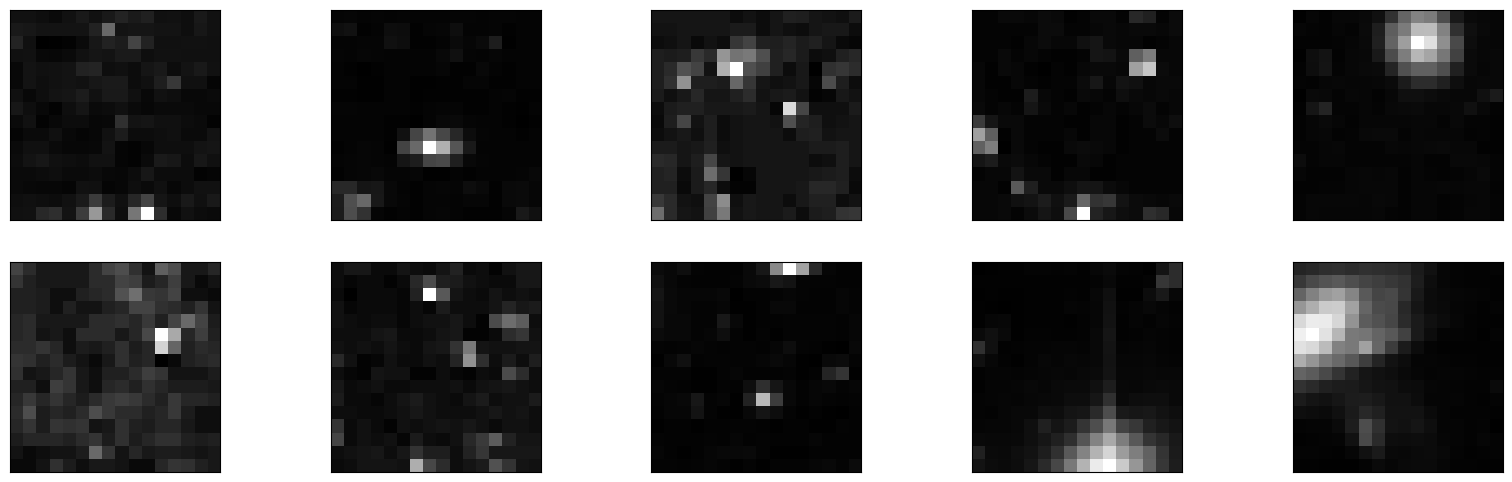

In [5]:
n_samples_show = 5
fig, axes = plt.subplots(nrows=2, ncols=n_samples_show, figsize=(20, 6))

for i in range(n_samples_show):

    axes[0,i].imshow(dataInput[i], cmap='gray')
    axes[0,i].set_xticks([])
    axes[0,i].set_yticks([])
    axes[1,i].imshow(dataInput[i+5], cmap='gray')
    axes[1,i].set_xticks([])
    axes[1,i].set_yticks([])    


In [6]:
import numpy as np
import torch

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.connectors import TorchConnector
from torch.optim import LBFGS
from torch.nn import NLLLoss

# Six-qubit model; each encoding layer uses 12 rotation parameters.
nqubits = 6
num_inputs = 16 * 16
encoding_layers = 22

def normalizeData(data):
    """Scale an image vector safely and normalize it to unit L2 norm."""
    data = np.asarray(data, dtype=np.float64).reshape(-1)

    if not np.all(np.isfinite(data)):
        raise ValueError("Input data contains NaN or infinite values.")

    max_value = np.max(np.abs(data))
    if max_value == 0:
        return data

    data = np.round(data / max_value, 6)
    norm = np.linalg.norm(data)

    if norm == 0:
        return data

    return data / norm


def encoding(qc, theta, L):
    """Append the data-encoding layers to an existing 6-qubit circuit."""
    expected = 2 * nqubits * L
    if len(theta) != expected:
        raise ValueError(
            f"encoding expects {expected} parameters for L={L}; "
            f"received {len(theta)}."
        )

    for qubit in range(nqubits):
        qc.h(qubit)

    count = 0
    for _ in range(L):
        for qubit in range(nqubits):
            qc.ry(theta[count], qubit)
            count += 1

        for qubit in range(nqubits - 1):
            qc.cx(qubit, qubit + 1)
        qc.cx(nqubits - 1, 0)

        for qubit in range(nqubits):
            qc.ry(theta[count], qubit)
            count += 1

        for qubit in range(nqubits - 1):
            qc.cx(qubit + 1, qubit)
        qc.cx(0, nqubits - 1)

    return qc


def circuit15(qc, theta):
    """Append PQC circuit 15: two rotation layers and entanglers."""
    expected = 2 * nqubits
    if len(theta) != expected:
        raise ValueError(
            f"circuit15 expects {expected} parameters; received {len(theta)}."
        )

    count = 0
    for qubit in range(nqubits):
        qc.ry(theta[count], qubit)
        count += 1

    for qubit in range(nqubits - 1):
        qc.cx(qubit, qubit + 1)
    qc.cx(0, nqubits - 1)

    for qubit in range(nqubits):
        qc.ry(theta[count], qubit)
        count += 1

    for qubit in range(nqubits - 1):
        qc.cx(qubit + 1, qubit)
    qc.cx(nqubits - 1, 0)

    return qc


def parity(x):
    """Map a measured bitstring integer to even/odd parity."""
    return bin(int(x)).count("1") % 2


# The 16x16 image contains 256 input features.
# The encoding circuit uses 22 * 12 = 264 rotation angles:
# 256 trainable input parameters followed by 8 fixed pi/2 angles.
param_x = list(ParameterVector("x", num_inputs))
encoding_angles = param_x + [np.pi / 2] * (
    2 * nqubits * encoding_layers - num_inputs
)

feature_map = QuantumCircuit(nqubits, name="FeatureMap")
encoding(feature_map, encoding_angles, encoding_layers)

# Trainable PQC ansatz: 12 independent trainable parameters.
param_y = list(ParameterVector("theta", 2 * nqubits))
ansatz = QuantumCircuit(nqubits, name="Ansatz")
circuit15(ansatz, param_y)

# Build one complete circuit by composing the two independent circuits.
qc = QuantumCircuit(nqubits, name="GalaxyDetectionQNN")
qc.compose(feature_map, inplace=True)
qc.compose(ansatz, inplace=True)

# Explicit lists preserve the intended order of image pixels and weights.
qnn2 = SamplerQNN(
    circuit=qc,
    input_params=param_x,
    weight_params=param_y,
    interpret=parity,
    output_shape=2
)

np.random.seed(3)
initial_weights = 0.1 * (
    2 * np.random.rand(qnn2.num_weights) - 1
)

print("QNN input parameters:", qnn2.num_inputs)
print("QNN trainable weights:", qnn2.num_weights)
print("Circuit qubits:", qc.num_qubits)


QNN input parameters: 256
QNN trainable weights: 12
Circuit qubits: 6


In [7]:
# Prepare the complete dataset for the QNN.
if len(dataInput) != len(data_target_o):
    raise ValueError("The number of images and labels does not match.")

X = np.asarray([normalizeData(image) for image in dataInput], dtype=np.float32)
y01 = np.asarray(data_target_o, dtype=np.int64)

if X.ndim != 2 or X.shape[1] != num_inputs:
    raise ValueError(
        f"Expected each image to contain {num_inputs} features; "
        f"received shape {X.shape}."
    )

if not np.isin(y01, [0, 1]).all():
    raise ValueError("Labels must be encoded as 0 or 1.")

print("X shape:", X.shape)
print("y shape:", y01.shape)
print("Class counts:", np.bincount(y01))


X shape: (50, 256)
y shape: (50,)
Class counts: [25 25]


In [8]:
import qiskit
import qiskit_machine_learning
import torch
import numpy as np

print("NumPy:", np.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit Machine Learning:", qiskit_machine_learning.__version__)
print("PyTorch:", torch.__version__)


NumPy: 2.5.4
Qiskit: 2.6.1
Qiskit Machine Learning: 0.9.1
PyTorch: 2.10.0


## Important notes before running

- The notebook expects the project helper modules in `../Pyfiles` (`ImageRead.py` and `QNN.py`) and the image folders referenced in the data-loading cells. Those files must exist relative to the notebook's working directory.
- Run cells from top to bottom after restarting the kernel. Do not repeatedly reinstall NumPy in the middle of a notebook session.
- The final evaluation uses a separate test dataset from `../dataset/Original/galaxy1/` and `../dataset/Original/no-galaxy1/`. Make sure these folders contain images that were not used in training.
- The `SamplerQNN` output is a probability vector. The training code therefore uses negative log-likelihood on log probabilities rather than treating probabilities as logits with `CrossEntropyLoss`.


In [10]:
# Train the QNN.
# SamplerQNN returns class probabilities, not raw logits.
# Therefore use negative log-likelihood on log(probabilities), not CrossEntropyLoss.

model2 = TorchConnector(qnn2, initial_weights)
optimizer = LBFGS(model2.parameters(), lr=0.05, max_iter=20)
loss_fn = NLLLoss()

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y01, dtype=torch.long)

def closure():
    optimizer.zero_grad()

    sample_losses = []
    for x, target in zip(X_tensor, y_tensor):
        probabilities = model2(x).reshape(1, 2)
        log_probabilities = torch.log(
            probabilities.clamp_min(1e-8)
        )
        sample_losses.append(
            loss_fn(log_probabilities, target.reshape(1))
        )

    loss = torch.stack(sample_losses).mean()
    loss.backward()
    return loss

model2.train()
for epoch in range(5):
    loss = optimizer.step(closure)
    print(f"Epoch {epoch + 1}: loss = {loss.item():.6f}")


Epoch 1: loss = 0.829526
Epoch 2: loss = 0.621136
Epoch 3: loss = 0.564021
Epoch 4: loss = 0.538363
Epoch 5: loss = 0.535885


In [18]:
import os

base_path = os.path.expanduser(
    '~/Downloads/Galaxy_Detection_Using_QML-main/jupyter notebooks/result'
)

print("Folder exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    print("Files:", os.listdir(base_path))

Folder exists: True
Files: ['0_8.jpg', '2_8.jpg', '.DS_Store', '4_8.jpg', '3_8.jpg', '1_8.jpg', '5_8.jpg', '5_7.jpg', '1_3.jpg', '3_1.jpg', '3_0.jpg', '1_2.jpg', '5_6.jpg', '5_4.jpg', '1_0.jpg', '3_2.jpg', '3_3.jpg', '1_1.jpg', '5_5.jpg', '5_1.jpg', '1_5.jpg', '3_7.jpg', '3_6.jpg', '1_4.jpg', '5_0.jpg', '5_2.jpg', '1_6.jpg', '3_4.jpg', '3_5.jpg', '1_7.jpg', '5_3.jpg', '2_2.jpg', '0_0.jpg', '4_4.jpg', '4_5.jpg', '0_1.jpg', '2_3.jpg', '2_1.jpg', '0_3.jpg', '4_7.jpg', '4_6.jpg', '0_2.jpg', '2_0.jpg', '2_4.jpg', '0_6.jpg', '4_2.jpg', '4_3.jpg', '0_7.jpg', '2_5.jpg', '2_7.jpg', '0_5.jpg', '4_1.jpg', '4_0.jpg', '0_4.jpg', '2_6.jpg']


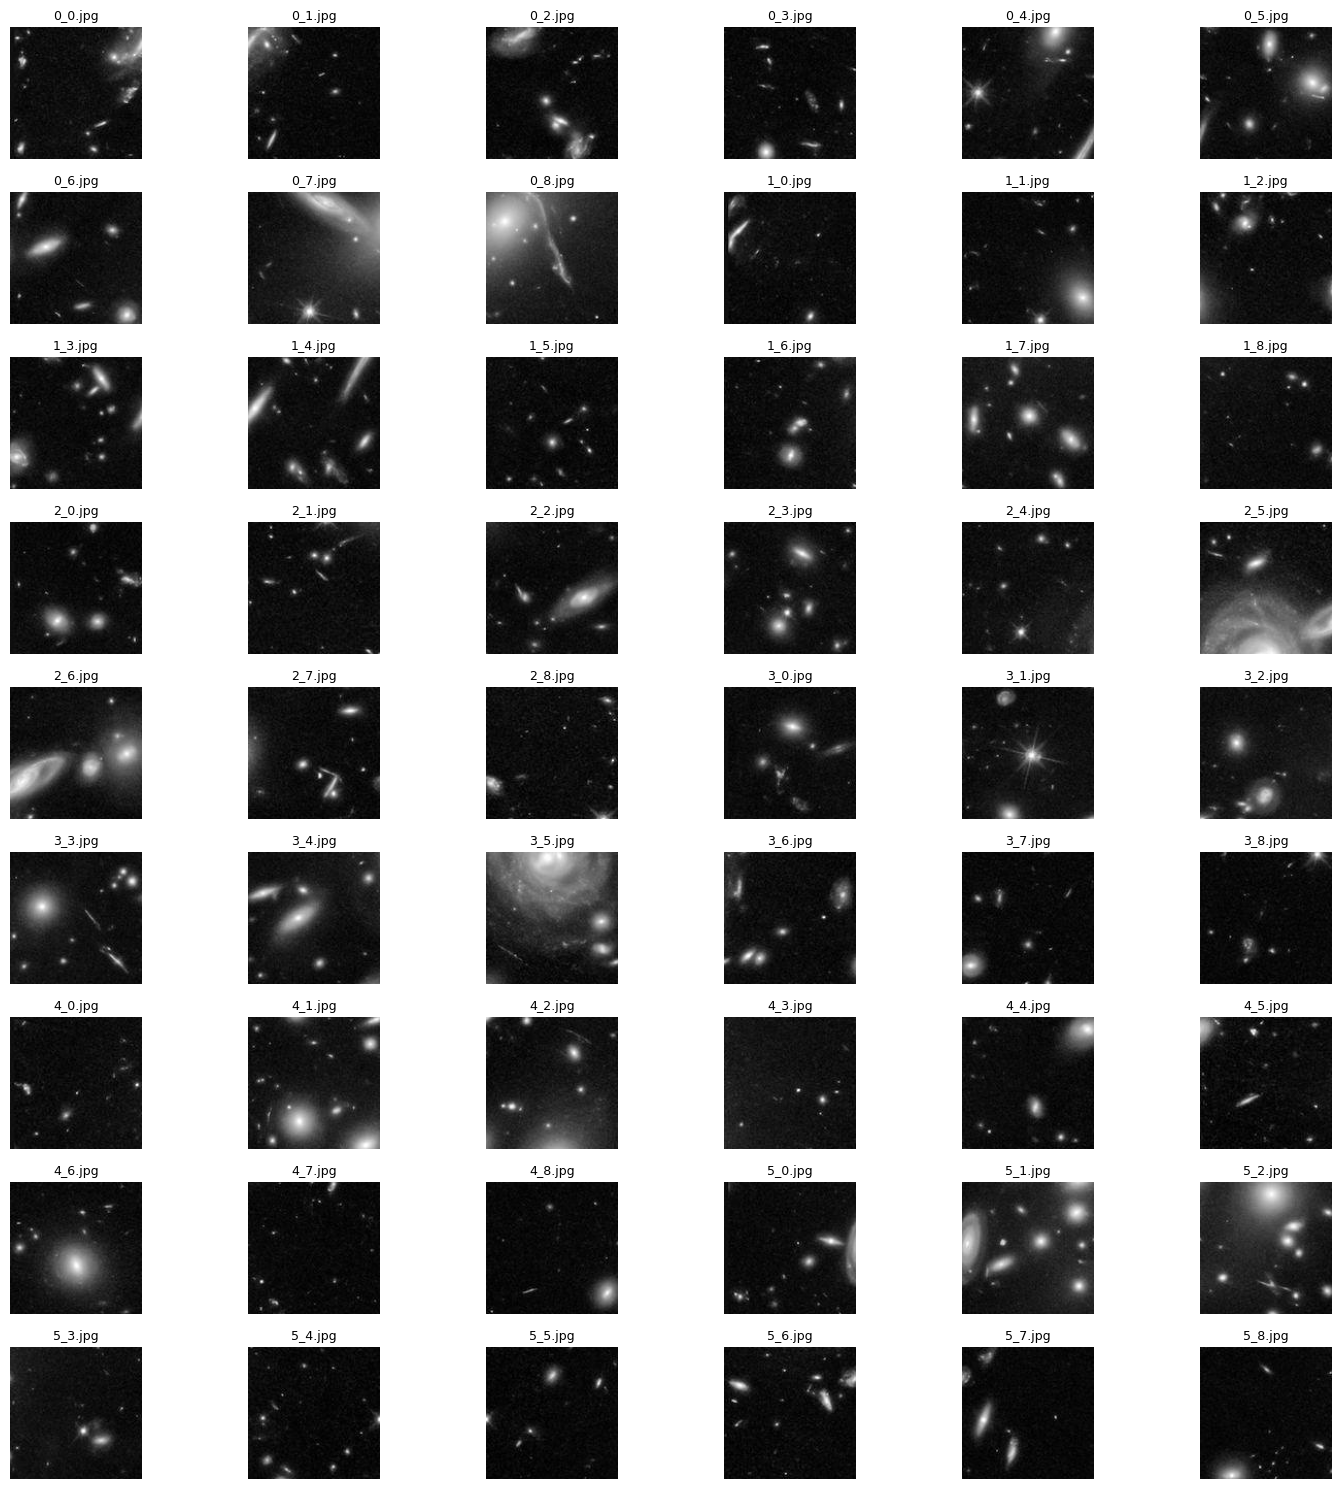

In [24]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import math

cols = 6
rows = math.ceil(len(image_files) / cols)

plt.figure(figsize=(15, 15))

for i, filename in enumerate(image_files):
    img_path = os.path.join(test_path, filename)
    img = Image.open(img_path).convert('L')

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(filename, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [28]:

import os

original_path = os.path.expanduser(
    '~/Downloads/Galaxy_Detection_Using_QML-main/images/dataset/Original'
)

print("Original dataset contents:\n")

for root, dirs, files in os.walk(original_path):
    level = root.replace(original_path, '').count(os.sep)
    indent = '    ' * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            print(f"{indent}    {file}")

    # Print folder image counts
    image_count = sum(
        1 for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    )

    if image_count:
        print(f"{indent}    [Total images: {image_count}]")


Original dataset contents:

Original/
    galaxy1/
        2_22.jpg
        8.jpg
        9.jpg
        14.jpg
        28.jpg
        29.jpg
        15.jpg
        17.jpg
        1_11.jpg
        16.jpg
        12.jpg
        13.jpg
        11.jpg
        10.jpg
        21.jpg
        35.jpg
        34.jpg
        20.jpg
        36.jpg
        22.jpg
        23.jpg
        37.jpg
        33.jpg
        27.jpg
        26.jpg
        32.jpg
        18.jpg
        24.jpg
        30.jpg
        31.jpg
        25.jpg
        19.jpg
        4.jpg
        5.jpg
        7.jpg
        6.jpg
        2.jpg
        3.jpg
        1.jpg
        [Total images: 39]
    galaxy/
        48.jpg
        49.jpg
        8.jpg
        9.jpg
        14.jpg
        28.jpg
        29.jpg
        15.jpg
        17.jpg
        16.jpg
        12.jpg
        13.jpg
        39.jpg
        11.jpg
        10.jpg
        38.jpg
        21.jpg
        35.jpg
        34.jpg
        20.jpg
        36.jpg
        22.jpg
  

In [30]:

import os
import json

notebook_path = os.path.expanduser(
    '~/Downloads/Galaxy_Detection_Using_QML-main/jupyter notebooks'
)

for filename in os.listdir(notebook_path):
    if filename.endswith('.ipynb'):
        filepath = os.path.join(notebook_path, filename)

        with open(filepath, 'r', encoding='utf-8') as f:
            notebook = json.load(f)

        print(f"\n{'='*60}")
        print("NOTEBOOK:", filename)

        for cell in notebook.get('cells', []):
            if cell.get('cell_type') == 'code':
                source = ''.join(cell.get('source', []))

                if any(keyword in source.lower() for keyword in [
                    'result', 'galaxy1', 'no-galaxy',
                    'imagecrop', 'savefig', 'imsave',
                    'callimage', 'image.resize'
                ]):
                    print("\n--- Matching code cell ---")
                    print(source[:3000])



NOTEBOOK: Galaxy_Detection_QNN.ipynb

--- Matching code cell ---
pathY=r'../images/dataset/Original/galaxy/'
pathN=r'../images/dataset/Original/No-galaxy/'
nameN=''
nameY=''
# a1 = imageResize(callImage(5,pathY,nameY),16)
# a2 = imageResize(callImage(29,pathY,nameY),16)
# # plt.imshow(a1,cmap='gray')
# plt.imshow(a2,cmap='gray')
# plt.imshow(b1,cmap='gray')
# plt.imshow(b2,cmap='gray')
inputY=[imageResize(callImage(i+1,pathY,nameY),16) for i in range(25)]
inputN=[imageResize(callImage(i+1,pathN,nameN),16) for i in range(25)]
input_combine = inputY+inputN

--- Matching code cell ---
target_o = [1 for i in range(25)]+[0 for i in range(25)]

pathY=r'../dataset/Original/galaxy1/'
pathN=r'../dataset/Original/no-galaxy1/'
nameN=''
nameY=''
inputY=[imageResize(callImage(i+1,pathY,nameY),16) for i in range(25)]
inputN=[imageResize(callImage(i+1,pathN,nameN),16) for i in range(25)]
input_combine = inputY+inputN

np.random.seed(0)
idx=np.array([int(i) for i in range(50)]).flatten()

np.random.s

In [34]:

import os
import hashlib

base = os.path.expanduser(
    '~/Downloads/Galaxy_Detection_Using_QML-main/images/dataset/Original'
)

train_folders = ['galaxy', 'No-galaxy']
test_folders = ['galaxy1', 'No-galaxy1']

def image_hashes(folder):
    hashes = {}
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            with open(path, 'rb') as f:
                hashes[filename] = hashlib.sha256(f.read()).hexdigest()

    return hashes

train_hashes = set()

for folder in train_folders:
    train_hashes.update(
        image_hashes(os.path.join(base, folder)).values()
    )

test_hashes = set()

for folder in test_folders:
    test_hashes.update(
        image_hashes(os.path.join(base, folder)).values()
    )

overlap = train_hashes.intersection(test_hashes)

print("Training images:", len(train_hashes))
print("Testing images:", len(test_hashes))
print("Exact duplicate images:", len(overlap))

if overlap:
    print("WARNING: Some test images also occur in training data.")
else:
    print("No exact file duplicates detected.")


Training images: 145
Testing images: 122
Exact duplicate images: 0
No exact file duplicates detected.


In [36]:

import os
import numpy as np
import torch
from PIL import Image

test_pathY = os.path.join(base, 'galaxy1')
test_pathN = os.path.join(base, 'No-galaxy1')

# Get actual available image filenames
galaxy_files = sorted([
    f for f in os.listdir(test_pathY)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

no_galaxy_files = sorted([
    f for f in os.listdir(test_pathN)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

# Select 25 images from each class
selected_galaxy = galaxy_files[:25]
selected_no_galaxy = no_galaxy_files[:25]

assert len(selected_galaxy) == 25
assert len(selected_no_galaxy) == 25

# Display selected filenames
print("Selected Galaxy images:")
print(selected_galaxy)

print("\nSelected No-Galaxy images:")
print(selected_no_galaxy)

# Load and preprocess images
test_images = []

for filename in selected_galaxy:
    img = Image.open(
        os.path.join(test_pathY, filename)
    ).convert('L')

    img_array = np.asarray(img, dtype=np.uint8)
    test_images.append(imageResize(img_array, 16))

for filename in selected_no_galaxy:
    img = Image.open(
        os.path.join(test_pathN, filename)
    ).convert('L')

    img_array = np.asarray(img, dtype=np.uint8)
    test_images.append(imageResize(img_array, 16))

# Assign correct labels
test_labels = np.array(
    [1] * 25 + [0] * 25,
    dtype=np.int64
)

# Normalize
X_test = np.asarray(
    [normalizeData(img.flatten()) for img in test_images],
    dtype=np.float32
)

y_test = test_labels.copy()

# Shuffle together
rng = np.random.default_rng(42)
order = rng.permutation(len(X_test))

X_test = X_test[order]
y_test = y_test[order]

# Feature validation
if X_test.shape[1] != num_inputs:
    raise ValueError(
        f"Expected {num_inputs} features, got {X_test.shape[1]}"
    )

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

print("\nTest dataset loaded successfully!")
print("X_test shape:", X_test.shape)
print("Class distribution:", np.bincount(y_test))
print("Tensor shape:", X_test_tensor.shape)


Selected Galaxy images:
['1.jpg', '10.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg', '18.jpg', '19.jpg', '1_11.jpg', '2.jpg', '20.jpg', '21.jpg', '22.jpg', '23.jpg', '24.jpg', '25.jpg', '26.jpg', '27.jpg', '28.jpg', '29.jpg', '2_22.jpg', '3.jpg']

Selected No-Galaxy images:
['17.jpg', '18.jpg', '19.jpg', '2.jpg', '20.jpg', '21.jpg', '22.jpg', '23.jpg', '24.jpg', '25.jpg', '26.jpg', '27.jpg', '28.jpg', '29.jpg', '3.jpg', '30.jpg', '31.jpg', '32.jpg', '33.jpg', '34.jpg', '35.jpg', '36.jpg', '37.jpg', '38.jpg', '39.jpg']

Test dataset loaded successfully!
X_test shape: (50, 256)
Class distribution: [25 25]
Tensor shape: torch.Size([50, 256])


QML MODEL EVALUATION
Accuracy: 82.00%

Classification Report:
              precision    recall  f1-score   support

   No Galaxy       0.74      1.00      0.85        25
      Galaxy       1.00      0.64      0.78        25

    accuracy                           0.82        50
   macro avg       0.87      0.82      0.81        50
weighted avg       0.87      0.82      0.81        50



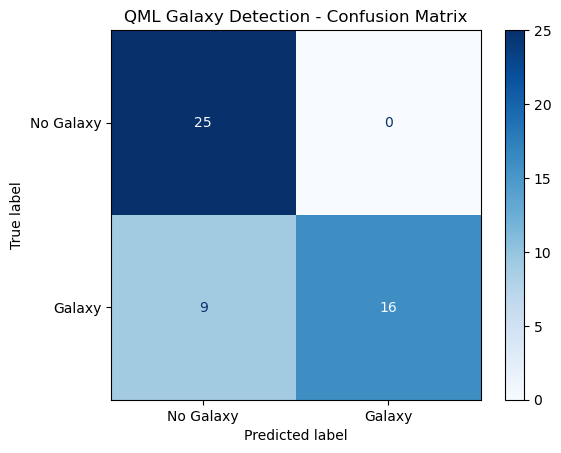

In [38]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

model2.eval()

y_pred = []

with torch.no_grad():
    for x in X_test_tensor:
        output = model2(x)
        prediction = torch.argmax(output).item()
        y_pred.append(prediction)

y_pred = np.array(y_pred)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("QML MODEL EVALUATION")
print("=" * 40)
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Galaxy', 'Galaxy'],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Galaxy', 'Galaxy']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("QML Galaxy Detection - Confusion Matrix")
plt.show()


In [40]:
# Evaluate on the separate held-out test dataset.
model2.eval()

test_predictions = []
with torch.no_grad():
    for x in X_test_tensor:
        probabilities = model2(x)
        test_predictions.append(int(torch.argmax(probabilities).item()))

test_predictions = np.asarray(test_predictions)
test_accuracy = np.mean(test_predictions == y_test)

print(f"Held-out test accuracy: {test_accuracy:.4f}")
print("Predictions:", test_predictions)
print("Actual labels:", y_test)


Held-out test accuracy: 0.8200
Predictions: [1 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0
 1 1 0 0 0 1 0 1 0 0 1 1 1]
Actual labels: [1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 1 0 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 1
 1 1 0 1 1 1 0 1 0 0 1 1 1]
